In [ ]:
# Task 30: Exploratory Data Analysis

## Objective
Perform exploratory data analysis on a student performance
dataset to identify meaningful patterns and relationships.

## Deliverables
- Complete EDA notebook
- Cleaned student dataset
- At least four meaningful visualizations
- Statistical analysis
- At least five observations
- EDA report and documentation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = {
    "student_id": [
        f"S{i:03d}" for i in range(1, 31)
    ],

    "gender": [
        "Female", "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female", "Male",
        "Female", "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female", "Male",
        "Female", "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female", "Male"
    ],

    "department": [
        "CSE", "ECE", "IT", "CSE", "ECE",
        "IT", "CSE", "ECE", "IT", "CSE",
        "ECE", "IT", "CSE", "ECE", "IT",
        "CSE", "ECE", "IT", "CSE", "ECE",
        "IT", "CSE", "ECE", "IT", "CSE",
        "ECE", "IT", "CSE", "ECE", "IT"
    ],

    "study_hours": [
        2.0, 3.5, 4.0, 1.5, 5.0,
        2.5, 6.0, 3.0, 7.0, 4.5,
        2.0, 5.5, 8.0, 3.5, 6.5,
        1.0, 4.0, 5.0, 7.5, 2.5,
        6.0, 3.0, 8.5, 4.5, 5.5,
        1.5, 7.0, 3.5, 6.5, 2.0
    ],

    "attendance_pct": [
        80, 85, 90, 75, 92,
        82, 95, 78, 96, 88,
        70, 86, 98, 84, 91,
        65, 89, 93, 97, 76,
        90, 81, 99, 87, 92,
        68, 94, 83, 95, 72
    ],

    "marks": [
        58, 65, 72, 52, 80,
        61, 88, 63, 91, 75,
        55, 81, 95, 68, 87,
        48, 73, 82, 93, 59,
        85, 64, 97, 76, 83,
        50, 90, 69, 89, 56
    ]
}

df = pd.DataFrame(data)

# Introduce four intentional missing values
df.loc[df["student_id"] == "S004", "department"] = np.nan
df.loc[df["student_id"] == "S007", "study_hours"] = np.nan
df.loc[df["student_id"] == "S012", "attendance_pct"] = np.nan
df.loc[df["student_id"] == "S019", "marks"] = np.nan

# Add one duplicate student record
duplicate_record = df[
    df["student_id"] == "S008"
].copy()

df_raw = pd.concat(
    [df, duplicate_record],
    ignore_index=True
)

print("Original dataset created successfully!")

print("Total records:", len(df_raw))
print("Total columns:", len(df_raw.columns))

display(df_raw.head(10))

Original dataset created successfully!
Total records: 31
Total columns: 6


,student_id,gender,department,study_hours,attendance_pct,marks
0,S001,Female,CSE,2.0,80.0,58.0
1,S002,Male,ECE,3.5,85.0,65.0
2,S003,Female,IT,4.0,90.0,72.0
3,S004,Male,NaN,1.5,75.0,52.0
4,S005,Female,ECE,5.0,92.0,80.0
5,S006,Male,IT,2.5,82.0,61.0
6,S007,Female,CSE,NaN,95.0,88.0
7,S008,Male,ECE,3.0,78.0,63.0
8,S009,Female,IT,7.0,96.0,91.0
9,S010,Male,CSE,4.5,88.0,75.0


In [3]:
# Save original dataset
df_raw.to_csv(
    "student_performance_raw.csv",
    index=False
)

# Reload the dataset
df_raw = pd.read_csv(
    "student_performance_raw.csv"
)

print("Original CSV loaded successfully!")

display(df_raw.head())

Original CSV loaded successfully!


,student_id,gender,department,study_hours,attendance_pct,marks
0,S001,Female,CSE,2.0,80.0,58.0
1,S002,Male,ECE,3.5,85.0,65.0
2,S003,Female,IT,4.0,90.0,72.0
3,S004,Male,NaN,1.5,75.0,52.0
4,S005,Female,ECE,5.0,92.0,80.0


In [4]:
print("DATASET DIMENSIONS")

print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])

print("\nColumn names:")
print(df_raw.columns.tolist())

DATASET DIMENSIONS
Rows: 31
Columns: 6

Column names:
['student_id', 'gender', 'department', 'study_hours', 'attendance_pct', 'marks']


In [5]:
print("DATA TYPES")

display(
    df_raw.dtypes.to_frame(
        name="Data Type"
    )
)

DATA TYPES


,Data Type
student_id,object
gender,object
department,object
study_hours,float64
attendance_pct,float64
marks,float64


In [6]:
print("FIRST FIVE RECORDS")

display(df_raw.head())

print("\nLAST FIVE RECORDS")

display(df_raw.tail())

FIRST FIVE RECORDS


,student_id,gender,department,study_hours,attendance_pct,marks
0,S001,Female,CSE,2.0,80.0,58.0
1,S002,Male,ECE,3.5,85.0,65.0
2,S003,Female,IT,4.0,90.0,72.0
3,S004,Male,NaN,1.5,75.0,52.0
4,S005,Female,ECE,5.0,92.0,80.0



LAST FIVE RECORDS


,student_id,gender,department,study_hours,attendance_pct,marks
26,S027,Female,IT,7.0,94.0,90.0
27,S028,Male,CSE,3.5,83.0,69.0
28,S029,Female,ECE,6.5,95.0,89.0
29,S030,Male,IT,2.0,72.0,56.0
30,S008,Male,ECE,3.0,78.0,63.0


In [7]:
print("DATASET INFORMATION")

df_raw.info()

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   student_id      31 non-null     object 
 1   gender          31 non-null     object 
 2   department      30 non-null     object 
 3   study_hours     30 non-null     float64
 4   attendance_pct  30 non-null     float64
 5   marks           30 non-null     float64
dtypes: float64(3), object(3)
memory usage: 1.6+ KB


In [8]:
print("MISSING VALUE ANALYSIS")

missing_counts = df_raw.isnull().sum()

display(
    missing_counts.to_frame(
        name="Missing Values"
    )
)

print(
    "\nTotal missing cells:",
    df_raw.isnull().sum().sum()
)

MISSING VALUE ANALYSIS


,Missing Values
student_id,0
gender,0
department,1
study_hours,1
attendance_pct,1
marks,1



Total missing cells: 4


In [9]:
print("DUPLICATE RECORD ANALYSIS")

duplicate_count = df_raw.duplicated(
    subset=["student_id"]
).sum()

print(
    "Duplicate student records:",
    duplicate_count
)

duplicate_rows = df_raw[
    df_raw.duplicated(
        subset=["student_id"],
        keep=False
    )
]

display(duplicate_rows)

DUPLICATE RECORD ANALYSIS
Duplicate student records: 1


,student_id,gender,department,study_hours,attendance_pct,marks
7,S008,Male,ECE,3.0,78.0,63.0
30,S008,Male,ECE,3.0,78.0,63.0


In [10]:
before_cleaning = len(df_raw)

df_cleaned = df_raw.drop_duplicates(
    subset=["student_id"],
    keep="first"
).copy()

after_duplicate_removal = len(df_cleaned)

duplicates_removed = (
    before_cleaning - after_duplicate_removal
)

print("BEFORE DUPLICATE REMOVAL:", before_cleaning)
print("DUPLICATES REMOVED:", duplicates_removed)
print("AFTER DUPLICATE REMOVAL:", after_duplicate_removal)

BEFORE DUPLICATE REMOVAL: 31
DUPLICATES REMOVED: 1
AFTER DUPLICATE REMOVAL: 30


In [11]:
missing_before = int(
    df_cleaned.isnull().sum().sum()
)

print(
    "Missing cells before treatment:",
    missing_before
)

display(
    df_cleaned.isnull().sum().to_frame(
        name="Missing Values"
    )
)

Missing cells before treatment: 4


,Missing Values
student_id,0
gender,0
department,1
study_hours,1
attendance_pct,1
marks,1


In [12]:
numerical_columns = [
    "study_hours",
    "attendance_pct",
    "marks"
]

for column in numerical_columns:

    median_value = df_cleaned[column].median()

    df_cleaned[column] = (
        df_cleaned[column].fillna(median_value)
    )

    print(
        f"{column}: Missing values filled with "
        f"median = {median_value}"
    )

study_hours: Missing values filled with median = 4.0
attendance_pct: Missing values filled with median = 88.0
marks: Missing values filled with median = 73.0


In [13]:
df_cleaned["department"] = (
    df_cleaned["department"].fillna("Unknown")
)

print("Missing department value handled!")

display(
    df_cleaned[
        ["student_id", "department"]
    ]
)

Missing department value handled!


,student_id,department
0,S001,CSE
1,S002,ECE
2,S003,IT
3,S004,Unknown
4,S005,ECE
5,S006,IT
6,S007,CSE
7,S008,ECE
8,S009,IT
9,S010,CSE


In [14]:
print("FINAL DATA QUALITY CHECK")

print(
    "Remaining missing values:",
    df_cleaned.isnull().sum().sum()
)

print(
    "Remaining duplicate student IDs:",
    df_cleaned.duplicated(
        subset=["student_id"]
    ).sum()
)

print(
    "Total cleaned records:",
    len(df_cleaned)
)

display(df_cleaned.head(10))

FINAL DATA QUALITY CHECK
Remaining missing values: 0
Remaining duplicate student IDs: 0
Total cleaned records: 30


,student_id,gender,department,study_hours,attendance_pct,marks
0,S001,Female,CSE,2.0,80.0,58.0
1,S002,Male,ECE,3.5,85.0,65.0
2,S003,Female,IT,4.0,90.0,72.0
3,S004,Male,Unknown,1.5,75.0,52.0
4,S005,Female,ECE,5.0,92.0,80.0
5,S006,Male,IT,2.5,82.0,61.0
6,S007,Female,CSE,4.0,95.0,88.0
7,S008,Male,ECE,3.0,78.0,63.0
8,S009,Female,IT,7.0,96.0,91.0
9,S010,Male,CSE,4.5,88.0,75.0


In [15]:
df_cleaned.to_csv(
    "student_performance_cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [16]:
print("DESCRIPTIVE STATISTICS")

display(
    df_cleaned[
        ["study_hours", "attendance_pct", "marks"]
    ].describe()
)

DESCRIPTIVE STATISTICS


,study_hours,attendance_pct,marks
count,30.000000,30.000000,30.000000
mean,4.350000,85.766667,72.833333
std,2.093298,9.372312,14.215299
min,1.000000,65.000000,48.000000
25%,2.625000,80.250000,61.500000
50%,4.000000,88.000000,73.000000
75%,5.875000,92.750000,84.500000
max,8.500000,99.000000,97.000000


In [17]:
department_summary = (
    df_cleaned[
        df_cleaned["department"] != "Unknown"
    ]
    .groupby("department")
    .agg(
        student_count=("student_id", "count"),
        average_marks=("marks", "mean"),
        median_marks=("marks", "median")
    )
    .reset_index()
)

department_summary["average_marks"] = (
    department_summary["average_marks"].round(2)
)

print("DEPARTMENT-WISE PERFORMANCE")

display(
    department_summary.sort_values(
        by="average_marks",
        ascending=False
    )
)

DEPARTMENT-WISE PERFORMANCE


,department,student_count,average_marks,median_marks
2,IT,10,78.10,81.5
0,CSE,9,72.56,73.0
1,ECE,10,69.90,66.5


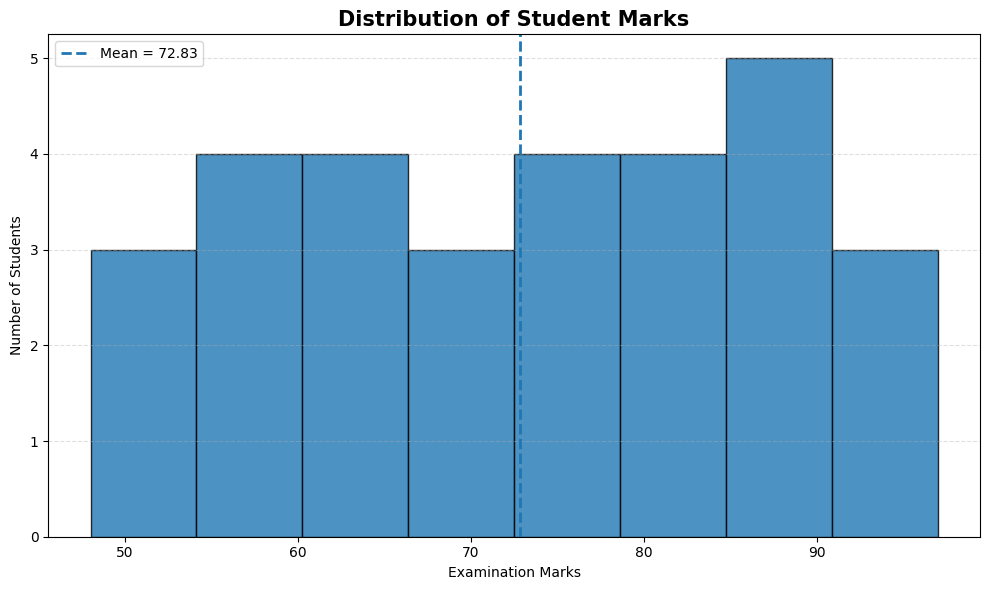

In [18]:
Path("charts").mkdir(exist_ok=True)

plt.figure(figsize=(10, 6))

plt.hist(
    df_cleaned["marks"],
    bins=8,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    df_cleaned["marks"].mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean = {df_cleaned['marks'].mean():.2f}"
)

plt.title(
    "Distribution of Student Marks",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Examination Marks")
plt.ylabel("Number of Students")

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "charts/marks_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

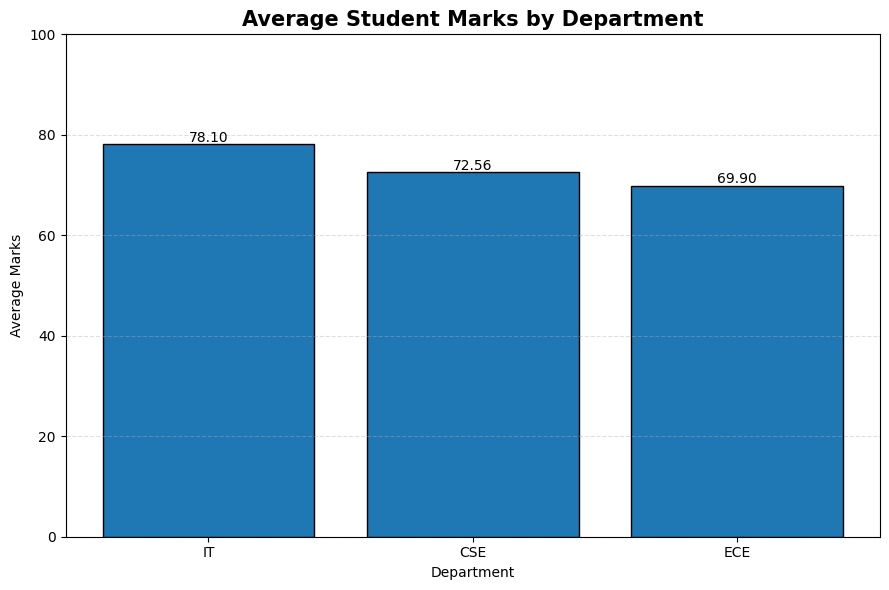

In [19]:
plot_data = department_summary.sort_values(
    by="average_marks",
    ascending=False
)

plt.figure(figsize=(9, 6))

bars = plt.bar(
    plot_data["department"],
    plot_data["average_marks"],
    edgecolor="black"
)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.2f}",
        ha="center"
    )

plt.title(
    "Average Student Marks by Department",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Department")
plt.ylabel("Average Marks")

plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "charts/average_marks_by_department.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

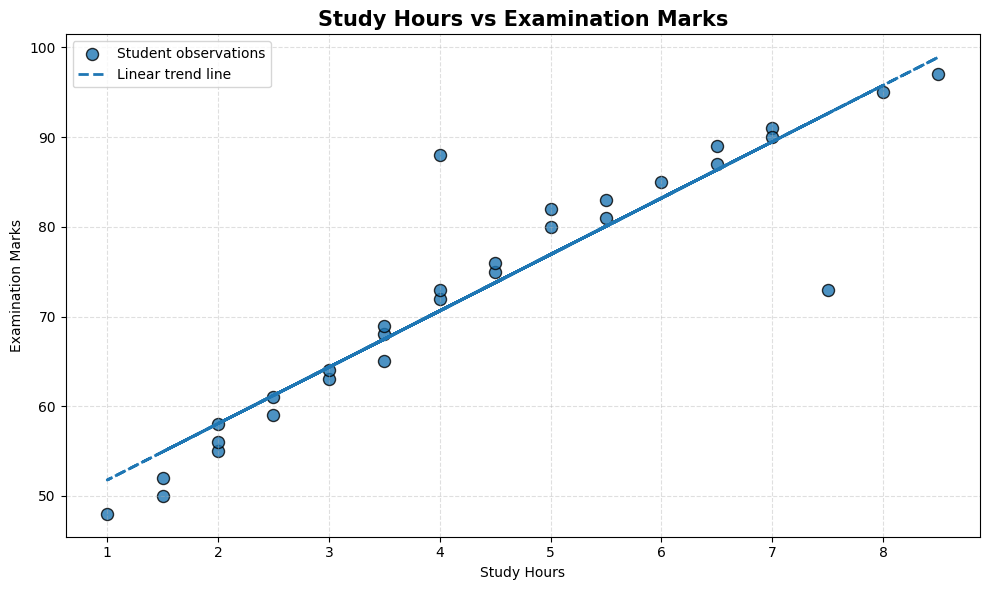

In [20]:
x = df_cleaned["study_hours"]
y = df_cleaned["marks"]

# Calculate linear trend line
slope, intercept = np.polyfit(x, y, 1)

trend_values = slope * x + intercept

plt.figure(figsize=(10, 6))

plt.scatter(
    x,
    y,
    s=75,
    edgecolors="black",
    alpha=0.8,
    label="Student observations"
)

plt.plot(
    x,
    trend_values,
    linestyle="--",
    linewidth=2,
    label="Linear trend line"
)

plt.title(
    "Study Hours vs Examination Marks",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Study Hours")
plt.ylabel("Examination Marks")

plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "charts/study_hours_vs_marks.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

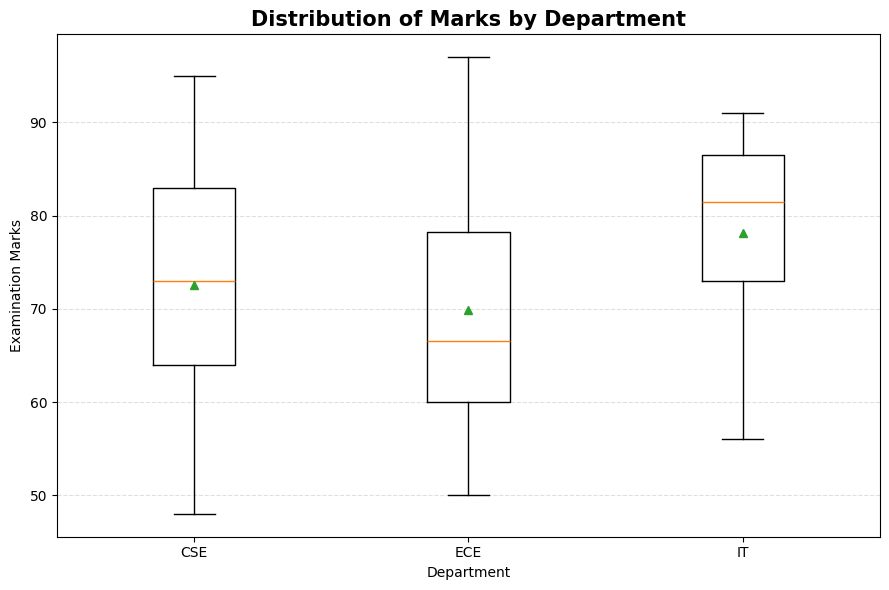

In [21]:
departments = ["CSE", "ECE", "IT"]

marks_by_department = [
    df_cleaned.loc[
        df_cleaned["department"] == department,
        "marks"
    ].values
    for department in departments
]

plt.figure(figsize=(9, 6))

plt.boxplot(
    marks_by_department,
    showmeans=True
)

plt.xticks(
    range(1, len(departments) + 1),
    departments
)

plt.title(
    "Distribution of Marks by Department",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Department")
plt.ylabel("Examination Marks")

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "charts/marks_by_department_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

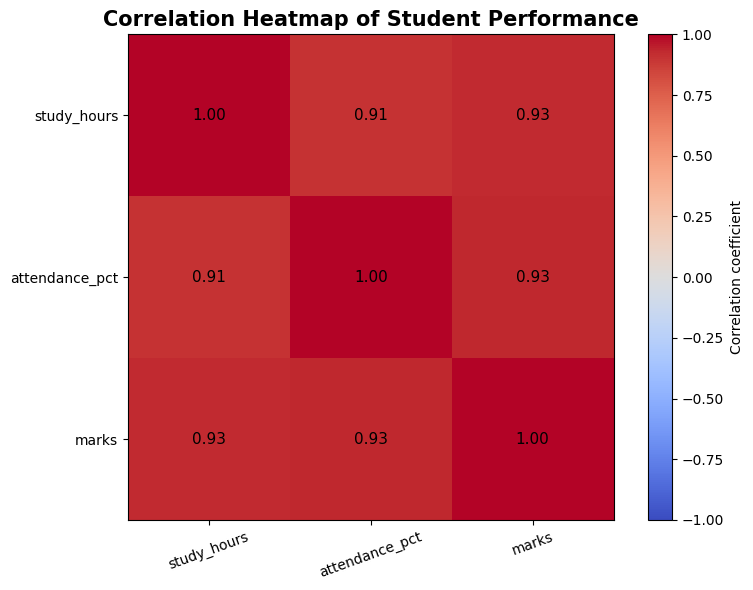

In [22]:
correlation_matrix = df_cleaned[
    ["study_hours", "attendance_pct", "marks"]
].corr()

plt.figure(figsize=(8, 6))

image = plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(
    image,
    label="Correlation coefficient"
)

columns = correlation_matrix.columns

plt.xticks(
    range(len(columns)),
    columns,
    rotation=20
)

plt.yticks(
    range(len(columns)),
    columns
)

# Add correlation values inside each cell
for i in range(len(columns)):
    for j in range(len(columns)):

        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=11
        )

plt.title(
    "Correlation Heatmap of Student Performance",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "charts/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
correlation_matrix = df_cleaned[
    ["study_hours", "attendance_pct", "marks"]
].corr()

print("CORRELATION MATRIX")

display(correlation_matrix)

study_marks_corr = correlation_matrix.loc[
    "study_hours", "marks"
]

attendance_marks_corr = correlation_matrix.loc[
    "attendance_pct", "marks"
]

study_attendance_corr = correlation_matrix.loc[
    "study_hours", "attendance_pct"
]

print(
    f"\nStudy hours vs marks: {study_marks_corr:.4f}"
)

print(
    f"Attendance vs marks: {attendance_marks_corr:.4f}"
)

print(
    f"Study hours vs attendance: {study_attendance_corr:.4f}"
)

CORRELATION MATRIX


,study_hours,attendance_pct,marks
study_hours,1.000000,0.905964,0.925605
attendance_pct,0.905964,1.000000,0.931971
marks,0.925605,0.931971,1.000000



Study hours vs marks: 0.9256
Attendance vs marks: 0.9320
Study hours vs attendance: 0.9060


In [24]:
# Calculate important findings

top_department = department_summary.loc[
    department_summary["average_marks"].idxmax()
]

lowest_department = department_summary.loc[
    department_summary["average_marks"].idxmin()
]

average_marks = df_cleaned["marks"].mean()
median_marks = df_cleaned["marks"].median()

average_study_hours = df_cleaned["study_hours"].mean()

average_attendance = df_cleaned["attendance_pct"].mean()

print("=" * 65)
print("             EXPLORATORY DATA ANALYSIS FINDINGS")
print("=" * 65)

print(
    f"\n1. The cleaned dataset contains "
    f"{len(df_cleaned)} student records."
)

print(
    f"\n2. Average examination marks are "
    f"{average_marks:.2f}, while median marks are "
    f"{median_marks:.2f}."
)

print(
    f"\n3. {top_department['department']} has the highest "
    f"average marks of {top_department['average_marks']:.2f}."
)

print(
    f"\n4. {lowest_department['department']} has the lowest "
    f"average marks of {lowest_department['average_marks']:.2f}."
)

print(
    f"\n5. Study hours and examination marks have a "
    f"correlation of {study_marks_corr:.4f}."
)

print(
    f"\n6. Attendance and examination marks have a "
    f"correlation of {attendance_marks_corr:.4f}."
)

print(
    f"\n7. Average student attendance is "
    f"{average_attendance:.2f}%."
)

print(
    f"\n8. Average study time is "
    f"{average_study_hours:.2f} hours."
)

             EXPLORATORY DATA ANALYSIS FINDINGS

1. The cleaned dataset contains 30 student records.

2. Average examination marks are 72.83, while median marks are 73.00.

3. IT has the highest average marks of 78.10.

4. ECE has the lowest average marks of 69.90.

5. Study hours and examination marks have a correlation of 0.9256.

6. Attendance and examination marks have a correlation of 0.9320.

7. Average student attendance is 85.77%.

8. Average study time is 4.35 hours.


In [25]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Original records",
        "Duplicate records removed",
        "Records after duplicate removal",
        "Missing cells before treatment",
        "Missing cells after treatment",
        "Final cleaned records",
        "Average study hours",
        "Average attendance",
        "Average marks",
        "Median marks",
        "Highest department average",
        "Lowest department average",
        "Study hours and marks correlation",
        "Attendance and marks correlation"
    ],

    "Value": [
        len(df_raw),
        duplicates_removed,
        after_duplicate_removal,
        missing_before,
        int(df_cleaned.isnull().sum().sum()),
        len(df_cleaned),
        round(average_study_hours, 2),
        round(average_attendance, 2),
        round(average_marks, 2),
        round(median_marks, 2),
        top_department["department"],
        lowest_department["department"],
        round(study_marks_corr, 4),
        round(attendance_marks_corr, 4)
    ]
})

print("FINAL EDA SUMMARY")

display(eda_summary)

FINAL EDA SUMMARY


,Metric,Value
0,Original records,31
1,Duplicate records removed,1
2,Records after duplicate removal,30
3,Missing cells before treatment,4
4,Missing cells after treatment,0
5,Final cleaned records,30
6,Average study hours,4.35
7,Average attendance,85.77
8,Average marks,72.83
9,Median marks,73.0


In [26]:
# Export cleaned dataset
df_cleaned.to_csv(
    "student_performance_cleaned.csv",
    index=False
)

# Export department summary
department_summary.to_csv(
    "department_summary.csv",
    index=False
)

# Export correlation matrix
correlation_matrix.to_csv(
    "correlation_matrix.csv"
)

# Export EDA summary
eda_summary.to_csv(
    "eda_summary.csv",
    index=False
)

print("All EDA project files exported successfully!")

All EDA project files exported successfully!


In [27]:
from google.colab import files

files.download("student_performance_raw.csv")

files.download("student_performance_cleaned.csv")

files.download("department_summary.csv")

files.download("correlation_matrix.csv")

files.download("eda_summary.csv")

files.download("charts/marks_distribution.png")

files.download("charts/average_marks_by_department.png")

files.download("charts/study_hours_vs_marks.png")

files.download("charts/marks_by_department_boxplot.png")

files.download("charts/correlation_heatmap.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (10 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>